# Chapitre 13 - Méthodes à prototypes (cours 1)

Ce premier notebook du chapitre 13 présente les **méthodes à prototypes** pour la
classification :

1. le **K-means** utilisé comme classifieur (section 13.2.1 du livre) ;
2. la **quantification vectorielle par apprentissage** (LVQ, section 13.2.2) ;
3. les **mélanges gaussiens** vus comme des prototypes « souples » (section 13.2.3) ;
4. l'étude comparative « facile / difficile » de la section 13.3.1 (partie K-means et LVQ).

Nous reproduisons les figures 13.1, 13.2 et le panneau de droite de la figure 13.5.
Les plus proches voisins font l'objet du second notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch13_prototypes as cp
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
set_style()

## 1. Cadre et notations

On dispose de $N$ couples d'apprentissage $(x_1, g_1), \dots, (x_N, g_N)$ où
$x_i \in \mathbb{R}^p$ est un vecteur de caractéristiques et $g_i \in \{1, \dots, K\}$
une étiquette de classe.

Une **méthode à prototypes** résume les données par un petit nombre de points
$m_1, \dots, m_M \in \mathbb{R}^p$, les *prototypes*, chacun muni d'une classe.
Un nouveau point $x$ est affecté à la classe du **prototype le plus proche** :

$$\hat G(x) = \text{classe de } m_{j^*}, \qquad j^* = \arg\min_{j} \|x - m_j\|.$$

La distance est la distance euclidienne, calculée après avoir **standardisé**
chaque variable (moyenne nulle, variance 1 sur l'échantillon d'apprentissage),
pour que des variables mesurées dans des unités différentes pèsent autant.

> **Intuition.** La règle « prototype le plus proche » découpe l'espace en
> **cellules de Voronoï** : la cellule de $m_j$ est l'ensemble des points plus
> proches de $m_j$ que de tous les autres prototypes. Chaque cellule est un polyèdre
> convexe (intersection de demi-espaces $\{x : \|x-m_j\| \le \|x - m_l\|\}$,
> et cette inégalité est linéaire en $x$ après développement des carrés).
> La frontière de décision est donc **linéaire par morceaux**.

Toute la difficulté est de choisir **combien** de prototypes utiliser et **où** les placer.

## 2. Une simulation à trois classes

Pour reproduire l'esprit de la figure 13.1, nous simulons trois classes en
dimension 2, chacune étant un **mélange de gaussiennes** : la classe $k$ possède
10 centres $\mu_{k1}, \dots, \mu_{k,10}$ (tirés autour d'un point de base) ;
une observation de la classe $k$ choisit un centre au hasard puis ajoute un
bruit $\mathcal N(0, \sigma^2 I_2)$.

Comme nous connaissons le modèle, nous pouvons calculer la **règle de Bayes**
$\arg\max_k \Pr(G = k \mid X = x)$ et sa frontière (courbe en pointillés violets
dans les figures).

In [2]:
rng = np.random.RandomState(2)
base = np.array([[-1.5, 1.0], [1.5, 1.0], [0.0, -1.5]])
means3 = [b + 0.8 * rng.randn(10, 2) for b in base]
sigma2_3 = 0.2
X3, y3 = cp.sample_gaussian_mixture(means3, 100, sigma2_3, rng)
X3_test, y3_test = cp.sample_gaussian_mixture(means3, 3000, sigma2_3, rng)
bayes3 = np.mean(cp.mixture_posterior(X3_test, means3, sigma2_3).argmax(1) != y3_test)
print("Apprentissage :", X3.shape, " test :", X3_test.shape)
print("Erreur de Bayes (estimée sur l'échantillon test) : %.3f" % bayes3)

Apprentissage : (300, 2)  test : (9000, 2)
Erreur de Bayes (estimée sur l'échantillon test) : 0.073


Une petite fonction de tracé, réutilisée dans tout le notebook : elle colore les
régions de décision d'un classifieur sur une grille, superpose les données, les
prototypes (gros points cerclés de noir) et la frontière de Bayes.

In [3]:
CMAP3 = ListedColormap(COLORS[:3])
PURPLE = COLORS[6]


def plot_regions(ax, predict, X, y, protos=None, proto_labels=None, bayes=None,
                 xlim=None, ylim=None, n=250, ncls=3):
    xlim = xlim or (X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
    ylim = ylim or (X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    xx, yy, grid = decision_grid(xlim, ylim, n)
    cmap = ListedColormap(COLORS[:ncls])
    Z = predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(ncls + 1) - 0.5, cmap=cmap, alpha=0.15)
    ax.contour(xx, yy, Z, levels=np.arange(ncls) + 0.5, colors="k", linewidths=1)
    if bayes is not None:
        B = bayes(grid).reshape(xx.shape)
        ax.contour(xx, yy, B, levels=np.arange(ncls) + 0.5, colors=PURPLE,
                   linewidths=1.5, linestyles="--")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, s=12, alpha=0.7, vmin=0, vmax=ncls - 1)
    if protos is not None:
        ax.scatter(protos[:, 0], protos[:, 1], c=proto_labels, cmap=cmap, s=90,
                   edgecolors="k", linewidths=1.5, vmin=0, vmax=ncls - 1)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")


bayes3_rule = lambda G: cp.mixture_posterior(G, means3, sigma2_3).argmax(1)

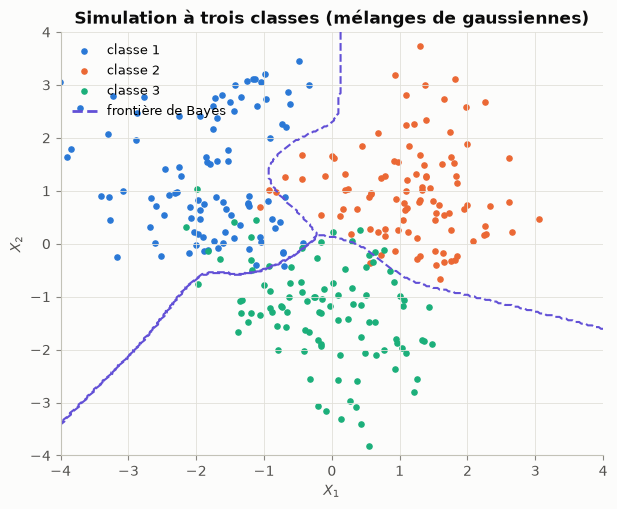

In [4]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for k in range(3):
    m = y3 == k
    ax.scatter(X3[m, 0], X3[m, 1], s=14, color=COLORS[k], label="classe %d" % (k + 1))
xx, yy, grid = decision_grid((-4, 4), (-4, 4), 250)
ax.contour(xx, yy, bayes3_rule(grid).reshape(xx.shape), levels=[0.5, 1.5],
           colors=PURPLE, linestyles="--", linewidths=1.5)
ax.plot([], [], "--", color=PURPLE, label="frontière de Bayes")
ax.set(title="Simulation à trois classes (mélanges de gaussiennes)",
       xlabel="$X_1$", ylabel="$X_2$", xlim=(-4, 4), ylim=(-4, 4))
ax.legend(loc="upper left")
plt.show()

## 3. Le K-means

### 3.1 Le critère

Le K-means (que l'on note ici avec $R$ centres, la lettre $K$ étant réservée au
nombre de classes) cherche $R$ centres $m_1, \dots, m_R$ et une affectation
$C(i) \in \{1, \dots, R\}$ de chaque point à un centre qui minimisent l'**inertie
intra-groupes**

$$J(C, m) = \sum_{i=1}^N \|x_i - m_{C(i)}\|^2 .$$

### 3.2 L'algorithme de Lloyd

Partant de centres initiaux (typiquement $R$ points tirés au hasard parmi les
données), on alterne :

1. **affectation** : à centres fixés, chaque point rejoint le centre le plus proche,
   $C(i) = \arg\min_r \|x_i - m_r\|^2$ ;
2. **mise à jour** : à affectation fixée, chaque centre devient la moyenne de son groupe,
   $m_r = \frac{1}{N_r} \sum_{C(i) = r} x_i$.

On itère jusqu'à ce que les affectations ne changent plus.

**Pourquoi le critère décroît-il ?**

* L'étape 1 minimise $J$ en $C$ à $m$ fixé : chaque terme $\|x_i - m_{C(i)}\|^2$ est
  rendu minimal individuellement, donc $J$ ne peut pas augmenter.
* L'étape 2 minimise $J$ en $m$ à $C$ fixé. En effet, pour un groupe $r$,
  la fonction $m \mapsto \sum_{C(i)=r} \|x_i - m\|^2$ est un polynôme du second degré
  strictement convexe ; son gradient $-2 \sum_{C(i)=r}(x_i - m)$ s'annule en
  $m = \bar x_r$, la moyenne du groupe, qui est donc l'unique minimum.

$J$ décroît à chaque étape et ne prend qu'un nombre fini de valeurs (il y a un
nombre fini d'affectations possibles) : l'algorithme **s'arrête en un nombre fini
d'itérations**, sur un minimum *local* (d'où l'intérêt de plusieurs redémarrages).

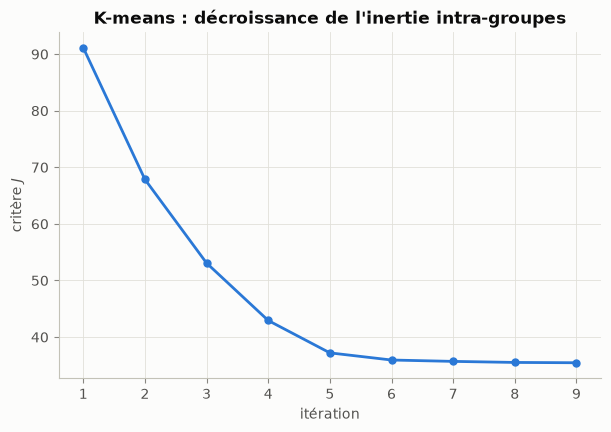

In [5]:
C, lab, inertia, hist = cp.kmeans(X3[y3 == 0], 5, n_init=1, rng=np.random.RandomState(3))
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(hist) + 1), hist, "o-", color=BLUE)
ax.set(title="K-means : décroissance de l'inertie intra-groupes",
       xlabel="itération", ylabel="critère $J$")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.show()

### 3.3 Le K-means comme classifieur

Pour des données **étiquetées**, on procède ainsi :

1. on applique le K-means **séparément dans chaque classe**, avec $R$ prototypes par classe ;
2. chacun des $K \times R$ prototypes reçoit l'étiquette de sa classe ;
3. un nouveau point est classé selon le prototype le plus proche.

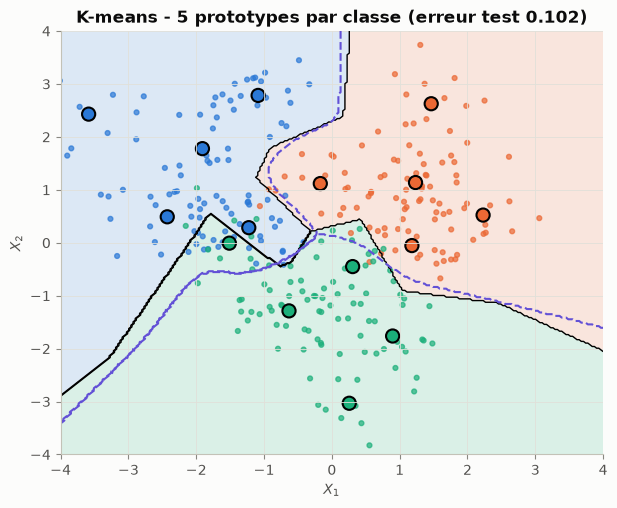

In [6]:
km3 = cp.KMeansClassifier(R=5, rng=np.random.RandomState(0)).fit(X3, y3)
err_km3 = np.mean(km3.predict(X3_test) != y3_test)

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_regions(ax, km3.predict, X3, y3, km3.prototypes_, km3.proto_labels_,
             bayes3_rule, (-4, 4), (-4, 4))
ax.set_title("K-means - 5 prototypes par classe (erreur test %.3f)" % err_km3)
plt.show()

> **Remarque.** Plusieurs prototypes se trouvent tout près de la frontière entre
> classes. C'est le défaut structurel de la méthode : quand on place les prototypes
> d'une classe, **les autres classes n'ont pas leur mot à dire**. Le K-means résume
> bien la distribution de chaque classe, mais il n'est pas conçu pour bien
> *discriminer*.

## 4. LVQ - quantification vectorielle par apprentissage

L'idée de Kohonen est d'utiliser **toutes** les données pour positionner **tous** les
prototypes : un point d'apprentissage *attire* les prototypes de sa classe et
*repousse* les autres.

**Algorithme LVQ1** (algorithme 13.1 du livre, reformulé).

1. Choisir $R$ prototypes initiaux par classe, $m_1(k), \dots, m_R(k)$ (par exemple
   la solution K-means, ou $R$ points tirés au hasard dans la classe $k$).
2. Tirer un point d'apprentissage $x_i$ au hasard (avec remise) et repérer le
   prototype le plus proche, $m_j(k)$.
   * si $g_i = k$ (même classe), on le **rapproche** : $m_j(k) \leftarrow m_j(k) + \epsilon\,(x_i - m_j(k))$ ;
   * si $g_i \ne k$, on l'**éloigne** : $m_j(k) \leftarrow m_j(k) - \epsilon\,(x_i - m_j(k))$.
3. Répéter l'étape 2 en faisant décroître le pas $\epsilon$ vers 0.

> **Intuition.** Le déplacement $\epsilon(x_i - m)$ fait parcourir au prototype une
> fraction $\epsilon$ du segment qui le sépare de $x_i$. Un prototype mal placé près de
> la frontière est sans cesse repoussé par les points de l'autre classe : il s'en
> écarte.

> **Remarque (pas d'apprentissage).** Comme pour le gradient stochastique
> (section 11.4), on prend des pas $\epsilon_t \to 0$. La théorie de
> l'approximation stochastique demande classiquement $\sum_t \epsilon_t = \infty$
> (pour pouvoir aller loin) et $\sum_t \epsilon_t^2 < \infty$ (pour que le bruit
> s'éteigne). Ici nous utilisons simplement une décroissance linéaire
> $\epsilon_t = \epsilon_0 (1 - t/T)$ sur un nombre fixé $T$ d'itérations.

Un défaut de LVQ : elle est définie par un **algorithme** et non par un critère à
optimiser, ce qui rend ses propriétés difficiles à analyser.

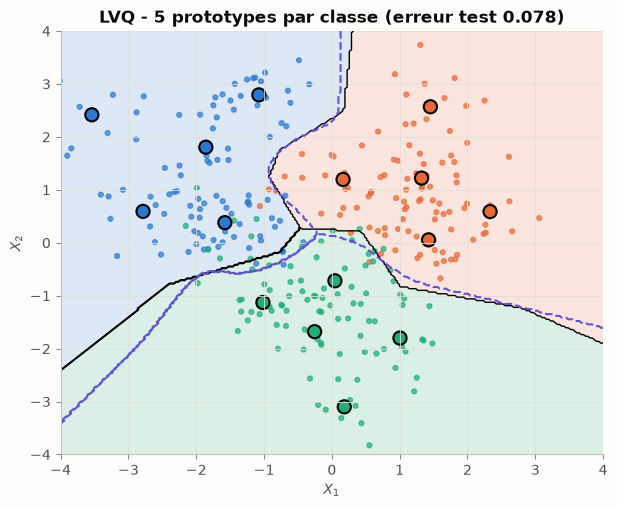

In [7]:
lvq3 = cp.LVQClassifier(R=5, eps0=0.1, rng=np.random.RandomState(0)).fit(X3, y3)
err_lvq3 = np.mean(lvq3.predict(X3_test) != y3_test)

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_regions(ax, lvq3.predict, X3, y3, lvq3.prototypes_, lvq3.proto_labels_,
             bayes3_rule, (-4, 4), (-4, 4))
ax.set_title("LVQ - 5 prototypes par classe (erreur test %.3f)" % err_lvq3)
plt.show()